# M13.9 y M13.10 — Protocolo corto y curva de aprendizaje en fuentes (G3T)

Pre-registros: `docs/experiments/M13_9_short_protocol.md` y `docs/experiments/M13_10_learning_curve.md` (6-11-2026). Este notebook aplica sus criterios sin cambiarlos. Todo se mide en val G3T; solo CPU.

**Modelos.** De las configs de `configs/experiments/m13/` solo se leen `checkpoint_tag` y `train_subset`.

| clave | config | papel |
|---|---|---|
| `long_s123` | `train_m13_13_4aG3T_s123.json` | 4a-G3T, 80 épocas, 400k fuentes: referencia de M13.9 y punto N = 400k de M13.10 |
| `short_s123`, `short_s124` | `train_m13_9_4aG3T_short20_s12{3,4}.json` | M13.9: 20 épocas, programa comprimido |
| `n200k` | `train_m13_10_4aG3T_n200k_s123.json` | M13.10: N = 200k (primaria), 124 960 pasos |
| `n100k` | `train_m13_10_4aG3T_n100k_s123.json` | M13.10: N = 100k (descriptiva), 124 960 pasos |

**M13.10.** G = RMSE(N)/RMSE(400k) − 1 por etiqueta, global y en D8–D10 de τ30. IC 95 % por bootstrap emparejado de filas de val (B = 2000, `default_rng(131002)`), con las mismas filas en numerador y denominador. Cada uno de los 6 G de 200k: ≥ 5 % limitado, < 2 % no limitado, resto no concluyente. Veredicto global: limitado por datos si al menos un G global o el G de χ_eff en D8–D10 es ≥ 5 %; no limitado si los 6 son < 2 %; no concluyente en el resto. El punto de 100k es descriptivo. P-AUG1 a posteriori: el monitor train40k se separa en filas entrenadas y no entrenadas.

**M13.9.** Penalización = media(RMSE_s123, RMSE_s124)/RMSE_largo − 1; ruido de semilla = |RMSE_s123 − RMSE_s124|/media; ambos en val global. Se adopta si la penalización es ≤ 5 % y el ruido de semilla ≤ 3 % en las tres etiquetas. Descriptivo, fuera del criterio: IC bootstrap de la penalización (B = 2000, `default_rng(131003)`) y los mismos valores en D8–D10.

**Límites.** Los IC remuestrean filas de val, no semillas ni entrenamientos. M13.10 tiene una semilla por punto.

Reutiliza de `M13_13_G3T_evaluation.ipynb`: carga y desestandarización (`load_pred`, celda 2), deciles de τ30 (celda 3) y `boot` (celda 5, con el generador como argumento). Cada generador se consume solo en su celda y en orden fijo (etiqueta × grupo).

In [1]:
# 1. Parámetros y procedencia
import hashlib
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse, as in M13_8, M13_12 and M13_13: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
OUT_DIR = M13_DIR / 'M13_9_10_analysis'
FIG_DIR = OUT_DIR / 'figures'
VAL_NPZ, TR_NPZ = 'val_predictions_embeddings.npz', 'train40k_predictions.npz'
CFG_DIR = ROOT / 'configs' / 'experiments' / 'm13'
REF_SUMMARY = M13_DIR / 'M13_6_evaluation_summary_20261102_1552.json'   # optional: tau_edges_s of M13_6, as in M13_8

# ---- Inputs: key -> (config, expected max_epochs, expected total_steps) -----------------------------------------
# Expected values from the pre-registrations (80 epochs and 124 960 steps; M13.9: 20 epochs = 31 240 steps) and the
# trainer change (n200k: 781 steps/epoch x 160; n100k: 390 x 321, cut at 124 960).
MODELS = {'long_s123': ('train_m13_13_4aG3T_s123.json', 80, 124960),
          'short_s123': ('train_m13_9_4aG3T_short20_s123.json', 20, 31240),
          'short_s124': ('train_m13_9_4aG3T_short20_s124.json', 20, 31240),
          'n200k': ('train_m13_10_4aG3T_n200k_s123.json', 160, 124960),
          'n100k': ('train_m13_10_4aG3T_n100k_s123.json', 321, 124960)}
MODEL_NAME = {'long_s123': '4a-G3T s123 (80 ép., 400k)', 'short_s123': 'corto s123 (20 ép.)',
              'short_s124': 'corto s124 (20 ép.)', 'n200k': 'N = 200k s123', 'n100k': 'N = 100k s123'}
conf = {k: json.loads((CFG_DIR / f).read_text()) for k, (f, _, _) in MODELS.items()}
TAG = {k: c['outputs']['checkpoint_tag'] for k, c in conf.items()}
SUBSET = {k: c['training'].get('train_subset') for k, c in conf.items()}
# -----------------------------------------------------------------------------------------------------------------

# Pre-registered settings.
N_BOOT = 2000
SEED_M13_10 = 131002               # bootstrap of G (M13.10)
SEED_M13_9 = 131003                # bootstrap of the penalty (M13.9, descriptive)
SUBSET_SEED = 131001               # nested train subsets (M13.10)
TOTAL_STEPS_M13_10 = 124960
N_SOURCES = {'n100k': 100000, 'n200k': 200000, 'long_s123': 400000}
G_LIMITED_PCT, G_NOT_LIMITED_PCT = 5.0, 2.0
PENALTY_MAX_PCT, SEED_NOISE_MAX_PCT = 5.0, 3.0
LC_GROUPS = ['global', 'D8-D10']   # groups of the M13.10 measure and of the M13.9 descriptive values
# Same tolerances and constants as M13_13.
Y_RTOL, Y_ATOL = 1e-5, 1e-6
TAU_EDGE_RTOL = 1e-6
G3T_MARK = 'm13_13_g3t'
CHUNK = 100                        # bootstrap replicates per vectorised block (memory only; does not change draws)
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')

all_files = {}
for k in MODELS:
    for kind, name in (('val', VAL_NPZ), ('train40k', TR_NPZ), ('run_info', 'run_info.json'), ('history', 'history.npz')):
        all_files[f'{kind}/{k}'] = M13_DIR / TAG[k] / name
missing = [f'{k}: {p}' for k, p in all_files.items() if not p.exists()]
require(not missing, f'Missing files (required): {missing}')

sha = {k: digest(p) for k, p in all_files.items()}
prov = pd.DataFrame([dict(file=k, path=str(p), size_mb=p.stat().st_size / 2**20,
                          mtime_utc=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
                          sha256_short=sha[k][:12]) for k, p in all_files.items()])
print(DATA_ROOT)
print('Run stamp:', RUN_UTC)
print('Tags:', TAG)
prov

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/traitlets/traitlets.py", line 632, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/ipykernel/kernelbase.py", line 347, in dispatch_control
    async with self._control_lock:
  File "/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/traitlets/traitlets.py", line 687, in __get__
    return t.cast(G, self.get(obj, cls))  # the G should encode the Optional
  File "/afs/ciemat.es/user/v/vserrano/min

/data/vserrano/cbc_pe_data
Run stamp: 20261110T155701Z
Tags: {'long_s123': 'M13_13_4a_G3T_s123', 'short_s123': 'M13_9_4a_G3T_short20_s123', 'short_s124': 'M13_9_4a_G3T_short20_s124', 'n200k': 'M13_10_4a_G3T_n200k_s123', 'n100k': 'M13_10_4a_G3T_n100k_s123'}


,file,path,size_mb,mtime_utc,sha256_short
0,val/long_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,10.004542,2026-11-07T00:19:54+00:00,92db8eb185ec
1,train40k/long_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,10.007058,2026-11-07T00:19:55+00:00,e634798aded4
2,run_info/long_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,0.006519,2026-11-06T11:37:54+00:00,406a70028347
3,history/long_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,0.016619,2026-11-07T00:19:54+00:00,7d70ebdaad23
4,val/short_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,10.038338,2026-11-07T03:32:59+00:00,9bd466568702
5,train40k/short_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,10.041203,2026-11-07T03:32:59+00:00,00c4dd30b6b5
6,run_info/short_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,0.006548,2026-11-07T00:23:36+00:00,9cb4ad02dccc
7,history/short_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,0.006948,2026-11-07T03:32:58+00:00,f5d2bf867aa8
8,val/short_s124,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,10.046453,2026-11-07T06:42:32+00:00,64b92f058e33
9,train40k/short_s124,/data/vserrano/cbc_pe_data/results/M13_3/M13_9...,10.049062,2026-11-07T06:42:33+00:00,a2a1b6b98807


In [2]:
# 2. GATES (require aborts on the first failure): same row ids and same labels in every input
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_pred(path, name, ckpt_expected, on_g3t, check_mean):
    # load_pred of M13_13 (cell 2), unchanged except that it also returns idx_val as stored (idx_raw).
    with np.load(path, allow_pickle=False) as a:
        f, y = a['pred_val'].astype(np.float64), a['y_val'].astype(np.float64)
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = Path(str(a['checkpoint_file'])).name if 'checkpoint_file' in a.files else None
        memmap_dir = str(a['memmap_dir']) if 'memmap_dir' in a.files else None
    n = len(idx)
    check(f.shape == y.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(np.isfinite(f).all() and np.isfinite(y).all(), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    if check_mean:
        check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    if on_g3t:
        check(ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected}')
        check(memmap_dir is not None and G3T_MARK in memmap_dir, f'{name}: memmap_dir is under {G3T_MARK}')
    else:
        check(ckpt_name is None or ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected} (if recorded)')
        check(memmap_dir is None or G3T_MARK not in memmap_dir, f'{name}: memmap_dir is not under {G3T_MARK} (if recorded)')
    o = np.argsort(idx)                # align every file on the HDF5 row id
    return dict(f=f[o], y=y[o], idx=idx[o], idx_raw=idx, units=units, ckpt=ckpt_name, memmap_dir=memmap_dir)


# Every model is trained and evaluated on G3T: on_g3t=True, check_mean=True.
pred = {k: load_pred(M13_DIR / TAG[k] / VAL_NPZ, k, f'{TAG[k]}_final.pt', True, True) for k in MODELS}

REF = 'long_s123'
IDX, Y = pred[REF]['idx'], pred[REF]['y']
check(np.array_equal(IDX, np.sort(splits['val'])), f'{REF}: idx_val equals val membership')
for k in MODELS:
    check(np.array_equal(pred[k]['idx_raw'], pred[REF]['idx_raw']), f'{k}: idx_val identical to {REF} (as stored)')
    print(f'{k}: max |y - y_ref| (physical) =', np.abs(pred[k]['y'] - Y).max(0))
    check(np.isclose(pred[k]['y'], Y, rtol=Y_RTOL, atol=Y_ATOL).all(), f'{k}: same labels as {REF}')
keys = list(MODELS)
for i, a in enumerate(keys):         # equal predictions would mean a duplicated file or checkpoint
    for b in keys[i + 1:]:
        check(not np.array_equal(pred[a]['f'], pred[b]['f']), f'{a} and {b} predictions differ')

P = {k: pred[k]['f'] for k in MODELS}  # physical units, columns in LABELS order
N = len(Y)
print('GATE passed:', len(checks), 'checks | n_val:', N, '| units in npz:', {k: pred[k]['units'] for k in MODELS})

long_s123: max |y - y_ref| (physical) = [0. 0. 0.]
short_s123: max |y - y_ref| (physical) = [0. 0. 0.]
short_s124: max |y - y_ref| (physical) = [0. 0. 0.]
n200k: max |y - y_ref| (physical) = [0. 0. 0.]
n100k: max |y - y_ref| (physical) = [0. 0. 0.]
GATE passed: 67 checks | n_val: 40000 | units in npz: {'long_s123': 'standardized', 'short_s123': 'standardized', 'short_s124': 'standardized', 'n200k': 'standardized', 'n100k': 'standardized'}


In [3]:
# 3. GATES de procedencia: run_info de la época final, total_steps y subconjuntos de train
# run_info.json is written at the start of a run; completion is checked with history.npz (every epoch present) and the
# _final.pt checkpoint named in the val npz (cell 2).
run_info = {}
for k, (_, max_ep, total) in MODELS.items():
    r = json.loads(all_files[f'run_info/{k}'].read_text())
    sch = r['procedure']['schedule']
    check(r['tag'] == TAG[k], f'{k}: run_info tag is {TAG[k]}')
    check(r['config']['outputs']['checkpoint_tag'] == TAG[k]
          and r['config']['training'].get('train_subset') == SUBSET[k], f'{k}: run_info config = repo config (tag, train_subset)')
    check(int(r['procedure']['max_epochs']) == max_ep, f'{k}: max_epochs = {max_ep}')
    check(int(sch['total_steps']) == total, f'{k}: total_steps = {total}')
    spe = int(sch['steps_per_epoch'])
    check((max_ep - 1) * spe < total <= max_ep * spe, f'{k}: total_steps ends in the last epoch ({spe} steps/epoch)')
    with np.load(all_files[f'history/{k}'], allow_pickle=False) as h:
        ep = h['epoch']
    check(np.array_equal(ep, np.arange(max_ep)), f'{k}: history has epochs 0..{max_ep - 1} (run reached the final epoch)')
    check(G3T_MARK in r['data']['memmap_dir'] and r['data']['memmap_dir'] == pred[k]['memmap_dir'],
          f'{k}: run_info memmap_dir = val npz memmap_dir (G3T)')
    check(('train_subset' in r['data']) == (SUBSET[k] is not None), f'{k}: run_info train_subset present iff configured')
    run_info[k] = r
for k in ('n200k', 'n100k'):
    check(int(run_info[k]['procedure']['schedule']['total_steps']) == TOTAL_STEPS_M13_10, f'{k}: total_steps = 124960 (M13.10)')

# Nested subsets recomputed as in train_m13_3.make_train_sampler: positions over the sorted row_ids_train.npy.
MM_DIR = Path(run_info[REF]['data']['memmap_dir'])
ROW_IDS_TRAIN = MM_DIR / 'row_ids_train.npy'
require(ROW_IDS_TRAIN.exists(), f'Missing {ROW_IDS_TRAIN}')
all_files['row_ids_train'] = ROW_IDS_TRAIN
sha['row_ids_train'] = digest(ROW_IDS_TRAIN)
row_ids_train = np.load(ROW_IDS_TRAIN).astype(np.int64)
n_train = int(run_info['n200k']['data']['n_train'])
check(all(int(r['data']['n_train']) == n_train for r in run_info.values()) and len(row_ids_train) == n_train == N_SOURCES[REF],
      'n_train = len(row_ids_train) = 400000 in every run_info')
check(np.array_equal(row_ids_train, np.sort(splits['train'])), 'row_ids_train equals train membership')
perm = np.random.default_rng(SUBSET_SEED).permutation(n_train)
TRAINED = {REF: row_ids_train}       # HDF5 row ids used in training (all of train for 400k)
for k in ('n200k', 'n100k'):
    ri = run_info[k]['data']['train_subset']
    check(SUBSET[k]['seed'] == ri['seed'] == SUBSET_SEED and SUBSET[k]['n'] == ri['n'] == N_SOURCES[k],
          f'{k}: train_subset n = {N_SOURCES[k]}, seed = {SUBSET_SEED}')
    rows = np.sort(row_ids_train[perm[:N_SOURCES[k]]]).astype(np.int64)
    check(hashlib.sha256(rows.tobytes()).hexdigest() == ri['row_ids_sha256'], f'{k}: recomputed subset reproduces row_ids_sha256')
    TRAINED[k] = rows
check(np.isin(TRAINED['n100k'], TRAINED['n200k']).all(), '100k subset nested in 200k')
prov_runs = pd.DataFrame([dict(model=k, tag=TAG[k], max_epochs=r['procedure']['max_epochs'],
                               steps_per_epoch=r['procedure']['schedule']['steps_per_epoch'],
                               warmup_steps=r['procedure']['schedule']['warmup_steps'],
                               total_steps=r['procedure']['schedule']['total_steps'],
                               n_sources=len(TRAINED[k]) if k in TRAINED else n_train,
                               seed=r['procedure']['sampler']['seed'], host=r['host'], gpu=r['gpu'], start=r['timestamp'])
                          for k, r in run_info.items()])
print('Provenance gates passed; total checks:', len(checks))
prov_runs

Provenance gates passed; total checks: 116


,model,tag,max_epochs,steps_per_epoch,warmup_steps,total_steps,n_sources,seed,host,gpu,start
0,long_s123,M13_13_4a_G3T_s123,80,1562,3124,124960,400000,123,Miguels_VM,Tesla P100-SXM2-16GB,2026-11-06T12:37:54
1,short_s123,M13_9_4a_G3T_short20_s123,20,1562,781,31240,400000,123,Miguels_VM,Tesla P100-SXM2-16GB,2026-11-07T01:23:36
2,short_s124,M13_9_4a_G3T_short20_s124,20,1562,781,31240,400000,124,Miguels_VM,Tesla P100-SXM2-16GB,2026-11-07T04:33:05
3,n200k,M13_10_4a_G3T_n200k_s123,160,781,3124,124960,200000,123,Miguels_VM,Tesla P100-SXM2-16GB,2026-11-07T07:42:39
4,n100k,M13_10_4a_G3T_n100k_s123,321,390,3124,124960,100000,123,Miguels_VM,Tesla P100-SXM2-16GB,2026-11-07T20:44:33


In [4]:
# 4. Grupos de tau30
# tau30 deciles: identical code to M13_13 cell 3 (Newtonian tau30 of the TRUE Mc, val quantile edges).
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
DEC = [f'D{d + 1}' for d in range(10)]
TAU_GROUPS = ['D1-D3', 'D4-D7', 'D8-D10']          # groups of M13_12
GROUP_NAMES = DEC + TAU_GROUPS + ['global']
GROUPS = {**{k: tdec == d for d, k in enumerate(DEC)}, 'D1-D3': tdec <= 2, 'D4-D7': (tdec >= 3) & (tdec <= 6),
          'D8-D10': tdec >= 7, 'global': np.ones(N, bool)}

ref_summary = json.loads(REF_SUMMARY.read_text()) if REF_SUMMARY.exists() else {}
if 'tau_edges_s' in ref_summary:
    check(np.allclose(tau_edges, ref_summary['tau_edges_s'], rtol=TAU_EDGE_RTOL, atol=0), 'tau30 decile edges equal M13_6 summary')
else:
    warnings.warn(f'{REF_SUMMARY.name}: tau_edges_s not available; edges not compared')
check(sum(int(GROUPS[k].sum()) for k in TAU_GROUPS) == N, 'tau groups partition val')
print('sizes:', {k: int(GROUPS[k].sum()) for k in LC_GROUPS})

sizes: {'global': 40000, 'D8-D10': 12000}


## M13.10 — Curva de aprendizaje
G en %, con las mismas filas remuestreadas para los tres modelos en cada réplica. Clasificación y veredicto sobre los valores puntuales de G(200k), con los umbrales del pre-registro; los IC se informan aparte.

In [5]:
# 5. M13.10: G = RMSE(N)/RMSE(400k) - 1 con IC 95 % (bootstrap emparejado de filas)
def rmse(f, y):
    return np.sqrt(np.mean((f - y)**2, -1))   # reduces over the last axis: (replicates, rows) -> one value per replicate


def boot(fn, arrays, rows, rng):
    # boot of M13_13 (cell 5), with the generator passed in: one index draw per replicate, shared by every array.
    xs = [a[rows] for a in arrays]
    n = len(xs[0])
    point = {k: float(v) for k, v in fn(*xs).items()}
    reps = {k: [] for k in point}
    for s in range(0, N_BOOT, CHUNK):
        ii = rng.integers(0, n, size=(min(CHUNK, N_BOOT - s), n))
        out = fn(*(x[ii] for x in xs))
        for k in reps:
            reps[k].append(out[k])
    return point, {k: np.concatenate(v) for k, v in reps.items()}


def ci(b):
    return np.percentile(b, [2.5, 97.5])


def lc_stats(f400, f200, f100, y):
    r400, r200, r100 = rmse(f400, y), rmse(f200, y), rmse(f100, y)
    return dict(rmse_400k=r400, rmse_200k=r200, rmse_100k=r100,
                G_200k_pct=100.0 * (r200 / r400 - 1.0), G_100k_pct=100.0 * (r100 / r400 - 1.0))


rng10 = np.random.default_rng(SEED_M13_10)   # consumed in this cell only, order: label x LC_GROUPS
rows = []
for j, label in enumerate(LABELS):
    for g in LC_GROUPS:
        m = GROUPS[g]
        pt, bt = boot(lc_stats, [P['long_s123'][:, j], P['n200k'][:, j], P['n100k'][:, j], Y[:, j]], m, rng10)
        rows += [dict(label=label, group=g, n=int(m.sum()), quantity=q, value=pt[q], ci95_lo=ci(bt[q])[0],
                      ci95_hi=ci(bt[q])[1], n_nan=int(np.isnan(bt[q]).sum())) for q in pt]
T10 = pd.DataFrame(rows)
check(T10.n_nan.sum() == 0, 'M13.10: bootstrap replicates without nan')
check(len(T10) == 5 * len(LABELS) * len(LC_GROUPS), 'M13.10: one row per quantity, label, group')


def classify_g(g):
    if g >= G_LIMITED_PCT:
        return 'limitado'
    return 'no limitado' if g < G_NOT_LIMITED_PCT else 'no concluyente'


G6 = T10[T10.quantity == 'G_200k_pct'][['label', 'group', 'n', 'value', 'ci95_lo', 'ci95_hi']].reset_index(drop=True)
G6['clase'] = G6.value.map(classify_g)
check(len(G6) == 6, 'M13.10: 6 values of G(200k)')
gv = {(r.label, r.group): r.value for r in G6.itertuples()}
# Combination rule of the pre-registration (doc M13.10, "Combinación").
limited = any(gv[(lab, 'global')] >= G_LIMITED_PCT for lab in LABELS) or gv[('chi_eff', 'D8-D10')] >= G_LIMITED_PCT
not_limited = all(v < G_NOT_LIMITED_PCT for v in gv.values())
VERDICT_M13_10 = 'limitado por datos' if limited else ('no limitado' if not_limited else 'no concluyente')
print('M13.10 veredicto global:', VERDICT_M13_10)
G6

M13.10 veredicto global: no concluyente


,label,group,n,value,ci95_lo,ci95_hi,clase
0,chirp_mass,global,40000,0.338906,-0.078711,0.761403,no limitado
1,chirp_mass,D8-D10,12000,0.458956,-0.707323,1.719521,no limitado
2,total_mass,global,40000,0.442555,-0.017866,0.907421,no limitado
3,total_mass,D8-D10,12000,0.525003,-0.586479,1.639153,no limitado
4,chi_eff,global,40000,0.872611,0.430162,1.328348,no limitado
5,chi_eff,D8-D10,12000,2.562300,1.414647,3.646906,no concluyente


In [6]:
# 6. M13.10: tabla completa (siempre)
def table(T, quantities, fmt):
    t = T[T.quantity.isin(quantities)].copy()
    t['txt'] = [f'{v:{fmt}} [{lo:{fmt}}, {hi:{fmt}}]' for v, lo, hi in zip(t.value, t.ci95_lo, t.ci95_hi)]
    w = t.pivot_table(index=['label', 'group'], columns='quantity', values='txt', aggfunc='first')
    return w.reindex(columns=quantities).reindex(index=[(lab, g) for lab in LABELS for g in LC_GROUPS])


display(table(T10, ['rmse_400k', 'rmse_200k', 'rmse_100k'], '.4g'))
display(table(T10, ['G_200k_pct', 'G_100k_pct'], '+.2f'))

quantity                         rmse_400k                rmse_200k  \
label      group                                                      
chirp_mass global      5.248 [5.18, 5.316]     5.266 [5.199, 5.334]   
           D8-D10     3.937 [3.754, 4.114]      3.955 [3.77, 4.133]   
total_mass global       8.76 [8.665, 8.86]     8.799 [8.701, 8.901]   
           D8-D10     7.318 [7.143, 7.498]      7.356 [7.177, 7.54]   
chi_eff    global  0.1677 [0.1662, 0.1693]  0.1691 [0.1676, 0.1708]   
           D8-D10   0.1746 [0.1714, 0.178]  0.1791 [0.1754, 0.1828]   

quantity                         rmse_100k  
label      group                            
chirp_mass global     5.307 [5.238, 5.376]  
           D8-D10     4.003 [3.822, 4.178]  
total_mass global     8.866 [8.766, 8.964]  
           D8-D10     7.375 [7.194, 7.573]  
chi_eff    global  0.1702 [0.1686, 0.1718]  
           D8-D10   0.1805 [0.177, 0.1841]

quantity                     G_200k_pct            G_100k_pct
label      group                                             
chirp_mass global  +0.34 [-0.08, +0.76]  +1.13 [+0.69, +1.57]
           D8-D10  +0.46 [-0.71, +1.72]  +1.67 [+0.48, +2.83]
total_mass global  +0.44 [-0.02, +0.91]  +1.22 [+0.78, +1.66]
           D8-D10  +0.53 [-0.59, +1.64]  +0.78 [-0.31, +1.84]
chi_eff    global  +0.87 [+0.43, +1.33]  +1.49 [+1.03, +1.95]
           D8-D10  +2.56 [+1.41, +3.65]  +3.37 [+2.20, +4.55]

In [7]:
# 7. M13.10: P-AUG1 a posteriori (monitor train40k separado en filas entrenadas y no entrenadas)
# Ratio MSE(train40k group)/MSE(val) per label, same model, last epoch. The ratio is the same in physical and in
# standardized units (per-label affine scaler). Descriptive: P-AUG1 threshold of M13.6 is 0.95 on all trained rows.
def load_train40k(k):
    with np.load(all_files[f'train40k/{k}'], allow_pickle=False) as a:
        f, y = a['pred_train'].astype(np.float64), a['y_train'].astype(np.float64)
        idx = a['idx_train'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        ckpt_name = Path(str(a['checkpoint_file'])).name
    check(f.shape == y.shape == (len(idx), 3) and label_names == LABELS, f'{k} train40k: shapes and label order')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{k} train40k: y_mean/y_std equal M11 train-only label stats')
    check(ckpt_name == f'{TAG[k]}_final.pt' and len(np.unique(idx)) == len(idx) and np.isfinite(f).all(),
          f'{k} train40k: final checkpoint, unique idx, finite')
    y, f, _ = npz_to_physical(y, f, c_mean, c_std)
    return dict(f=f, y=y, idx=idx)


PAUG_MODELS = ['long_s123', 'n200k', 'n100k']
tr40 = {k: load_train40k(k) for k in PAUG_MODELS}
for k in PAUG_MODELS:
    check(np.array_equal(tr40[k]['idx'], tr40[REF]['idx']), f'{k} train40k: same monitor rows as {REF}')
check(np.isin(tr40[REF]['idx'], row_ids_train).all(), 'train40k rows are train rows')

rows = []
for k in PAUG_MODELS:
    mse_val = np.mean((P[k] - Y)**2, 0)
    member = np.isin(tr40[k]['idx'], TRAINED[k])
    for grp, m in (('entrenadas', member), ('no entrenadas', ~member), ('todas', np.ones_like(member))):
        if not m.any():
            continue
        mse = np.mean((tr40[k]['f'][m] - tr40[k]['y'][m])**2, 0)
        rows.append(dict(model=k, rows=grp, n=int(m.sum()),
                         **{f'mse_{lab}': float(mse[j]) for j, lab in enumerate(LABELS)},
                         **{f'mse_val_{lab}': float(mse_val[j]) for j, lab in enumerate(LABELS)},
                         **{f'ratio_{lab}': float(mse[j] / mse_val[j]) for j, lab in enumerate(LABELS)}))
PAUG = pd.DataFrame(rows)
PAUG

,model,rows,n,mse_chirp_mass,mse_total_mass,mse_chi_eff,mse_val_chirp_mass,mse_val_total_mass,mse_val_chi_eff,ratio_chirp_mass,ratio_total_mass,ratio_chi_eff
0,long_s123,entrenadas,40000,27.078117,75.010230,0.027328,27.541292,76.733720,0.028115,0.983183,0.977539,0.972021
1,long_s123,todas,40000,27.078117,75.010230,0.027328,27.541292,76.733720,0.028115,0.983183,0.977539,0.972021
2,n200k,entrenadas,20009,27.370563,75.905762,0.027607,27.728286,77.414401,0.028608,0.987099,0.980512,0.965034
3,n200k,no entrenadas,19991,27.373848,75.936148,0.028258,27.728286,77.414401,0.028608,0.987217,0.980905,0.987786
4,n200k,todas,40000,27.372205,75.920948,0.027933,27.728286,77.414401,0.028608,0.987158,0.980708,0.976405
5,n100k,entrenadas,9958,26.063312,73.125929,0.027331,28.167573,78.614220,0.028960,0.925295,0.930187,0.943742
6,n100k,no entrenadas,30042,28.369323,78.893167,0.028753,28.167573,78.614220,0.028960,1.007162,1.003548,0.992834
7,n100k,todas,40000,27.795242,77.457413,0.028399,28.167573,78.614220,0.028960,0.986782,0.985285,0.980612


## M13.9 — Protocolo corto
Criterio sobre val global (valores puntuales). El IC de la penalización y los valores en D8–D10 son descriptivos y no entran en el criterio. No se da IC del ruido de semilla: remuestrear filas no mide la variación entre semillas.

In [8]:
# 8. M13.9: penalización y ruido de semilla
def short_stats(f_long, f_s123, f_s124, y):
    rl, r3, r4 = rmse(f_long, y), rmse(f_s123, y), rmse(f_s124, y)
    mean_short = 0.5 * (r3 + r4)
    return dict(rmse_long=rl, rmse_s123=r3, rmse_s124=r4, penalty_pct=100.0 * (mean_short / rl - 1.0),
                seed_noise_pct=100.0 * np.abs(r3 - r4) / mean_short)


rng9 = np.random.default_rng(SEED_M13_9)     # consumed in this cell only, order: label x LC_GROUPS
rows = []
for j, label in enumerate(LABELS):
    for g in LC_GROUPS:
        m = GROUPS[g]
        pt, bt = boot(short_stats, [P['long_s123'][:, j], P['short_s123'][:, j], P['short_s124'][:, j], Y[:, j]], m, rng9)
        for q in pt:
            lo, hi = (np.nan, np.nan) if q == 'seed_noise_pct' else ci(bt[q])
            rows.append(dict(label=label, group=g, n=int(m.sum()), quantity=q, value=pt[q], ci95_lo=lo, ci95_hi=hi,
                             n_nan=int(np.isnan(bt[q]).sum())))
T9 = pd.DataFrame(rows)
check(T9.n_nan.sum() == 0, 'M13.9: bootstrap replicates without nan')
check(len(T9) == 5 * len(LABELS) * len(LC_GROUPS), 'M13.9: one row per quantity, label, group')

# Pre-registered criterion: val global, point values, all three labels.
glob = T9[T9.group == 'global'].pivot(index='label', columns='quantity', values='value').reindex(LABELS)
C9 = pd.DataFrame({'penalty_pct': glob.penalty_pct, 'penalty_ok': glob.penalty_pct <= PENALTY_MAX_PCT,
                   'seed_noise_pct': glob.seed_noise_pct, 'seed_noise_ok': glob.seed_noise_pct <= SEED_NOISE_MAX_PCT})
ADOPT_M13_9 = bool(C9.penalty_ok.all() and C9.seed_noise_ok.all())
DECISION_M13_9 = 'se adopta' if ADOPT_M13_9 else 'no se adopta'
print('M13.9:', DECISION_M13_9)
C9

M13.9: no se adopta


,penalty_pct,penalty_ok,seed_noise_pct,seed_noise_ok
label,,,,
chirp_mass,4.076156,True,0.310803,True
total_mass,6.182912,False,0.926557,True
chi_eff,7.219672,False,1.002395,True


In [9]:
# 9. M13.9: tabla completa (global = criterio; D8-D10 = descriptivo)
def table9(quantities, fmt):
    t = T9[T9.quantity.isin(quantities)].copy()
    t['txt'] = [f'{v:{fmt}}' if np.isnan(lo) else f'{v:{fmt}} [{lo:{fmt}}, {hi:{fmt}}]'
                for v, lo, hi in zip(t.value, t.ci95_lo, t.ci95_hi)]
    w = t.pivot_table(index=['label', 'group'], columns='quantity', values='txt', aggfunc='first')
    return w.reindex(columns=quantities).reindex(index=[(lab, g) for lab in LABELS for g in LC_GROUPS])


display(table9(['rmse_long', 'rmse_s123', 'rmse_s124'], '.4g'))
display(table9(['penalty_pct', 'seed_noise_pct'], '+.2f'))

quantity                         rmse_long                rmse_s123  \
label      group                                                      
chirp_mass global     5.248 [5.179, 5.321]     5.453 [5.381, 5.522]   
           D8-D10      3.937 [3.76, 4.118]     4.223 [4.049, 4.395]   
total_mass global      8.76 [8.667, 8.855]      9.258 [9.161, 9.36]   
           D8-D10      7.318 [7.13, 7.502]     7.984 [7.797, 8.175]   
chi_eff    global  0.1677 [0.1661, 0.1692]  0.1789 [0.1772, 0.1806]   
           D8-D10  0.1746 [0.1713, 0.1778]  0.1958 [0.1921, 0.1993]   

quantity                         rmse_s124  
label      group                            
chirp_mass global        5.47 [5.4, 5.541]  
           D8-D10     4.247 [4.074, 4.418]  
total_mass global     9.344 [9.244, 9.451]  
           D8-D10     8.188 [7.999, 8.379]  
chi_eff    global  0.1807 [0.1791, 0.1824]  
           D8-D10  0.1984 [0.1947, 0.2021]

quantity                       penalty_pct seed_noise_pct
label      group                                         
chirp_mass global     +4.08 [+3.55, +4.59]          +0.31
           D8-D10     +7.57 [+5.90, +9.21]          +0.58
total_mass global     +6.18 [+5.63, +6.73]          +0.93
           D8-D10   +10.49 [+9.08, +11.88]          +2.53
chi_eff    global     +7.22 [+6.72, +7.74]          +1.00
           D8-D10  +12.89 [+11.65, +14.10]          +1.35

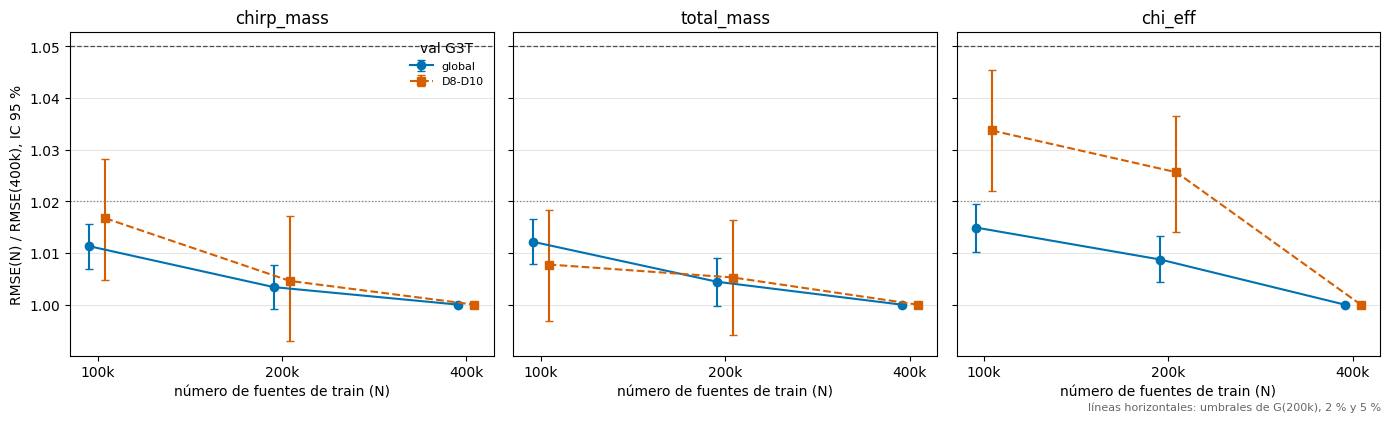

In [10]:
# 10. Figura: curva de aprendizaje (RMSE(N)/RMSE(400k), IC 95 %)
FIG_DIR.mkdir(parents=True, exist_ok=True)
NS = np.array([100000, 200000, 400000])
STYLE = {'global': dict(color='#0072B2', marker='o', ls='-', off=0.97),
         'D8-D10': dict(color='#D55E00', marker='s', ls='--', off=1.03)}
Tk = T10.set_index(['quantity', 'label', 'group'])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, lab in zip(axes, LABELS):
    for g, s in STYLE.items():
        rel, lo, hi = [], [], []
        for q in ('G_100k_pct', 'G_200k_pct'):
            r = Tk.loc[(q, lab, g)]
            rel.append(1 + r.value / 100)
            lo.append(1 + r.ci95_lo / 100)
            hi.append(1 + r.ci95_hi / 100)
        rel, lo, hi = np.array(rel + [1.0]), np.array(lo + [1.0]), np.array(hi + [1.0])   # 400k = reference
        ax.errorbar(NS * s['off'], rel, yerr=[rel - lo, hi - rel], color=s['color'], marker=s['marker'], ls=s['ls'],
                    ms=6, lw=1.5, capsize=3, label=g)
    ax.axhline(1 + G_NOT_LIMITED_PCT / 100, color='0.5', ls=':', lw=0.9)
    ax.axhline(1 + G_LIMITED_PCT / 100, color='0.3', ls='--', lw=0.9)
    ax.set_xscale('log')
    ax.set_xticks(NS)
    ax.set_xticklabels(['100k', '200k', '400k'])
    ax.minorticks_off()
    ax.set(title=lab, xlabel='número de fuentes de train (N)')
    ax.grid(axis='y', color='0.9', lw=0.8)
axes[0].set_ylabel('RMSE(N) / RMSE(400k), IC 95 %')
axes[0].legend(fontsize=8, frameon=False, title='val G3T')
fig.text(0.99, 0.01, 'líneas horizontales: umbrales de G(200k), 2 % y 5 %', ha='right', fontsize=8, color='0.4')
fig.tight_layout()
fig.savefig(FIG_DIR / f'M13_10_learning_curve_{RUN_UTC}.png', dpi=200)
plt.show()

In [ ]:
# 11. Resumen JSON (modo 'x': nunca sobrescribe)
OUT_DIR.mkdir(parents=True, exist_ok=True)
records = lambda df: json.loads(df.to_json(orient='records'))
summary = dict(
    experiment='M13.9 + M13.10', run_utc=RUN_UTC, split='val G3T', n_val=N, labels=LABELS,
    preregistration=dict(m13_9='docs/experiments/M13_9_short_protocol.md', m13_10='docs/experiments/M13_10_learning_curve.md'),
    note='CIs: paired row bootstrap of val, not seed or training variation. M13.10: one seed per point.',
    models={k: dict(tag=TAG[k], name=MODEL_NAME[k], config=MODELS[k][0], train_subset=SUBSET[k]) for k in MODELS},
    settings=dict(n_boot=N_BOOT, seed_m13_10=SEED_M13_10, seed_m13_9=SEED_M13_9, subset_seed=SUBSET_SEED,
                  total_steps_m13_10=TOTAL_STEPS_M13_10, g_limited_pct=G_LIMITED_PCT, g_not_limited_pct=G_NOT_LIMITED_PCT,
                  penalty_max_pct=PENALTY_MAX_PCT, seed_noise_max_pct=SEED_NOISE_MAX_PCT, y_rtol=Y_RTOL, y_atol=Y_ATOL),
    inputs={k: dict(path=str(p), sha256=sha[k]) for k, p in all_files.items()},
    runs=records(prov_runs),
    tau_edges_s=tau_edges.tolist(), group_sizes={k: int(GROUPS[k].sum()) for k in LC_GROUPS},
    gates=dict(passed=True, n_checks=len(checks), checks=checks),
    m13_10=dict(verdict=VERDICT_M13_10, g_200k_classified=records(G6), measures=records(T10), paug1_posthoc=records(PAUG)),
    m13_9=dict(decision=DECISION_M13_9, adopted=ADOPT_M13_9, criterion=records(C9.reset_index()), measures=records(T9)))

out_path = OUT_DIR / f'M13_9_10_analysis_summary_{RUN_UTC}.json'
with open(out_path, 'x') as fh:
    json.dump(summary, fh, indent=1, ensure_ascii=False)
print(out_path)

/data/vserrano/cbc_pe_data/results/M13_3/M13_9_10_analysis/M13_9_10_analysis_summary_20261110T155701Z.json


## Lectura — M13.10

M13.10. Veredicto según la regla: no concluyente. Cinco de los seis G(200k) son < 2 %; χ_eff en D8–D10 da +2,56 % [1,41; 3,65]. Ningún IC llega al 5 %, así que se descarta un efecto ≥ 5 % (con IC de filas, que no incluyen la variación entre semillas, ~2 %). G(100k) ≤ 3,4 %. P-AUG1 a posteriori: con 100k aparece memorización (cociente 0,93–0,94 en las filas entrenadas frente a 0,99–1,01 en las no entrenadas); con 200k solo en χ_eff. Lectura: el número de fuentes no es una palanca importante; χ_eff en señales largas es la etiqueta más sensible.

## Lectura — M13.9

M13.9. No se adopta: la penalización frente a 80 épocas es +4,1 / +6,2 / +7,2 % (umbral 5 %) y llega a +7,6 / +10,5 / +12,9 % en D8–D10. El ruido de semilla (0,3–1,0 %) sí cumple. El protocolo corto es estable, pero está sesgado frente al largo. Las variantes de M14 se evalúan con 80 épocas.